### Elderly Housing List
This notebook aims to answer the client question: What housing options are available/deed restricted for elderly individuals?  

#### Import Packages

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

#### Import Dataset
This data set contains the housing available for elderly residents in district 6. The exploratory data analysis has two sections: General Housing that showcases the overall unit statistics and Elderly Housing that shares insights on specific unit statistics for elderly residents. 

In [47]:
df = pd.read_csv("../dataset/elderly-housing-list-district-6-clean.csv", low_memory=False)

In [48]:
df

,neighborhood,zip,name_of_development,masshousing_number,site_address,site_address_telephone_number,management_company,management_company_telephone_number,PB_subsidy,MH_financed,FAM,ELD,bedroom_size_0_1,bedroom_size_2_3,bedroom_size_4_and_more,access_units,POINT_X,POINT_Y
0,Jamaica Plain,2130,91 MINDEN STREET,94-038,91 MINDEN STREET,(617) 524-7788,"Peabody Properties, Inc.",(617) 524-7788,True,False,1,0,1,0,0,0,42.325248,-71.105328
1,Jamaica Plain,2130,ANGELA WESTOVER HOUSE,00-105,49 PARLEY AVE,(617) 524-4520,"Peabody Properties, Inc.",(781) 794-1000,True,False,0,11,11,0,0,0,42.314007,-71.111019
2,Jamaica Plain,2130,DOMICILIA III,00-160,40 GREEN ST,(617) 600-2447,"Domicilia - UCP, Inc.",(617) 600-2448,True,False,8,0,0,8,0,8,42.312738,-71.111594
3,Jamaica Plain,2130,FARNSWORTH HOUSE,00-167,90 SOUTH ST,(617) 524-6971,"Rogerson Communities, Inc.",(617) 469-5830,True,True,1,75,69,7,0,8,42.306748,-71.115079
4,Jamaica Plain,2130,FOREST HILLS,01-366,177 FOREST HILLS ST,(617) 524-8254,"Trinity Management, LLC",(617) 542-9185,True,False,87,0,28,59,0,0,42.306086,-71.102921
5,Jamaica Plain,2130,FORESTVALE,01-367,14 ROCKVALE CIR,(617) 522-1829,"Reliant Realty Services, Inc.",(646) 734-6420,True,True,108,0,1,107,0,0,42.307723,-71.104096
6,Jamaica Plain,2130,POND VIEW APARTMENTS,00-269,560 CENTRE ST,(617) 522-4520,"Peabody Properties, Inc.",(781) 794-1000,True,False,56,0,35,21,0,0,42.316283,-71.113559
7,Roslindale,2131,CONWAY COURT,74-005,1 CONWAY STREET,(617) 574-1107,Beacon Residential Management,(617) 574-1100,False,True,28,0,14,14,0,0,42.287852,-71.130223
8,Roslindale,2131,CUMMINS TOWERS,01-508,855 AMERICAN LEGION,(617) 327-4810,First Realty Management Co.,(617) 423-7000,True,False,239,0,123,116,0,2,42.278947,-71.116853
9,Roslindale,2131,FLORENCE APTS,01-365,73 BRADEEN ST,(617) 327-2280,"Reliant Realty Services, Inc.",(917) 654-1750,True,True,138,0,0,138,0,0,42.289897,-71.120061


In [49]:
df = pd.read_csv("elderly-housing-list-district-6-clean.csv", dtype={
    'neighborhood': 'string',
    'zip': 'int64', 
    'name_of_development': 'string',
    'masshousing_number': 'string',
    'site_address': 'string', 
    'site_address_telephone_number': 'string', 
    'management_company': 'string', 
    'management_company_telephone_number': 'string', 
    'PB_subsidy': 'bool', 
    'MH_financed': 'bool', 
    'FAM': 'int64', 
    'ELD': 'int64', 
    'bedroom_size_0_1': 'int64', 
    'bedroom_size_2_3': 'int64',
    'bedroom_size_4_and_more':'int64',
    'access_units': 'int64', 
    'POINT_X': 'float64', 
    'POINT_Y': 'float64'
})

print(df.dtypes)

neighborhood                           string[python]
zip                                             int64
name_of_development                    string[python]
masshousing_number                     string[python]
site_address                           string[python]
site_address_telephone_number          string[python]
management_company                     string[python]
management_company_telephone_number    string[python]
PB_subsidy                                       bool
MH_financed                                      bool
FAM                                             int64
ELD                                             int64
bedroom_size_0_1                                int64
bedroom_size_2_3                                int64
bedroom_size_4_and_more                         int64
access_units                                    int64
POINT_X                                       float64
POINT_Y                                       float64
dtype: object


In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 18 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   neighborhood                         22 non-null     string 
 1   zip                                  22 non-null     int64  
 2   name_of_development                  22 non-null     string 
 3   masshousing_number                   22 non-null     string 
 4   site_address                         22 non-null     string 
 5   site_address_telephone_number        22 non-null     string 
 6   management_company                   22 non-null     string 
 7   management_company_telephone_number  22 non-null     string 
 8   PB_subsidy                           22 non-null     bool   
 9   MH_financed                          22 non-null     bool   
 10  FAM                                  22 non-null     int64  
 11  ELD                               

In [51]:
df['site_address'] = df['site_address'].str.upper()

In [52]:
df

,neighborhood,zip,name_of_development,masshousing_number,site_address,site_address_telephone_number,management_company,management_company_telephone_number,PB_subsidy,MH_financed,FAM,ELD,bedroom_size_0_1,bedroom_size_2_3,bedroom_size_4_and_more,access_units,POINT_X,POINT_Y
0,Jamaica Plain,2130,91 MINDEN STREET,94-038,91 MINDEN STREET,(617) 524-7788,"Peabody Properties, Inc.",(617) 524-7788,True,False,1,0,1,0,0,0,42.325248,-71.105328
1,Jamaica Plain,2130,ANGELA WESTOVER HOUSE,00-105,49 PARLEY AVE,(617) 524-4520,"Peabody Properties, Inc.",(781) 794-1000,True,False,0,11,11,0,0,0,42.314007,-71.111019
2,Jamaica Plain,2130,DOMICILIA III,00-160,40 GREEN ST,(617) 600-2447,"Domicilia - UCP, Inc.",(617) 600-2448,True,False,8,0,0,8,0,8,42.312738,-71.111594
3,Jamaica Plain,2130,FARNSWORTH HOUSE,00-167,90 SOUTH ST,(617) 524-6971,"Rogerson Communities, Inc.",(617) 469-5830,True,True,1,75,69,7,0,8,42.306748,-71.115079
4,Jamaica Plain,2130,FOREST HILLS,01-366,177 FOREST HILLS ST,(617) 524-8254,"Trinity Management, LLC",(617) 542-9185,True,False,87,0,28,59,0,0,42.306086,-71.102921
5,Jamaica Plain,2130,FORESTVALE,01-367,14 ROCKVALE CIR,(617) 522-1829,"Reliant Realty Services, Inc.",(646) 734-6420,True,True,108,0,1,107,0,0,42.307723,-71.104096
6,Jamaica Plain,2130,POND VIEW APARTMENTS,00-269,560 CENTRE ST,(617) 522-4520,"Peabody Properties, Inc.",(781) 794-1000,True,False,56,0,35,21,0,0,42.316283,-71.113559
7,Roslindale,2131,CONWAY COURT,74-005,1 CONWAY STREET,(617) 574-1107,Beacon Residential Management,(617) 574-1100,False,True,28,0,14,14,0,0,42.287852,-71.130223
8,Roslindale,2131,CUMMINS TOWERS,01-508,855 AMERICAN LEGION,(617) 327-4810,First Realty Management Co.,(617) 423-7000,True,False,239,0,123,116,0,2,42.278947,-71.116853
9,Roslindale,2131,FLORENCE APTS,01-365,73 BRADEEN ST,(617) 327-2280,"Reliant Realty Services, Inc.",(917) 654-1750,True,True,138,0,0,138,0,0,42.289897,-71.120061


#### General Housing EDA

In [53]:
plt.rcParams['font.family'] = 'Courier'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['font.size'] = 12

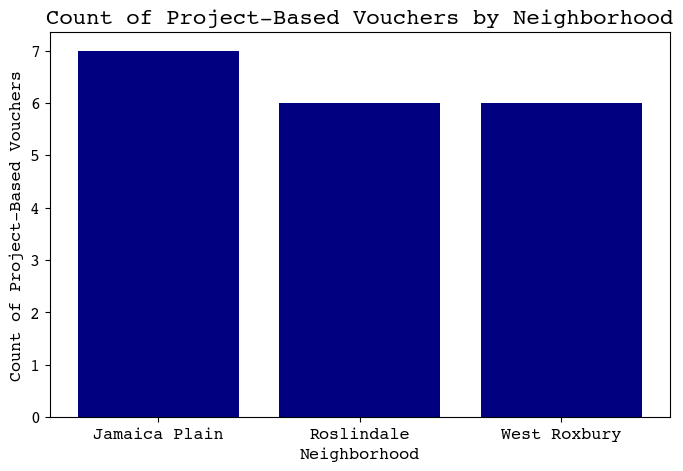

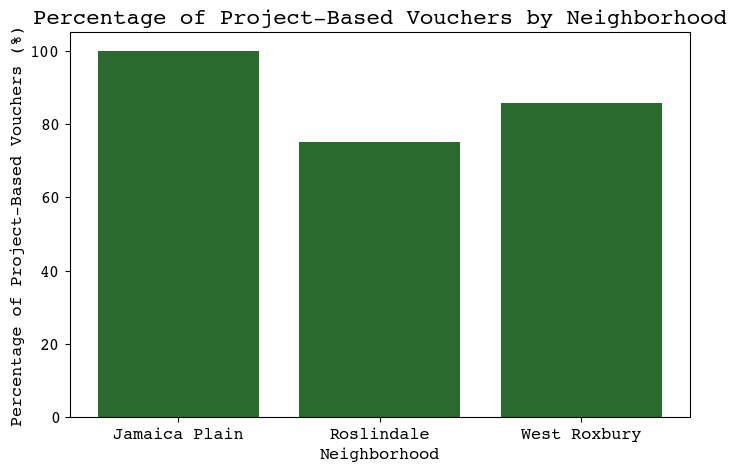

In [54]:
# Count of PBV families per neighborhood
pbv_counts = df.groupby('neighborhood')['PB_subsidy'].sum()
total_counts = df['neighborhood'].value_counts()
pbv_percentage = (pbv_counts / total_counts) * 100

# Plot 1: Count of Families with PBV
plt.figure(figsize=(8, 5))
plt.bar(pbv_counts.index, pbv_counts, color='navy')
plt.xlabel("Neighborhood")
plt.ylabel("Count of Project-Based Vouchers")
plt.title("Count of Project-Based Vouchers by Neighborhood")
plt.xticks(rotation=0)
plt.show()

# Plot 2: Percentage of Families with PBV
plt.figure(figsize=(8, 5))
plt.bar(pbv_percentage.index, pbv_percentage, color='#2C6B2F')
plt.xlabel("Neighborhood")
plt.ylabel("Percentage of Project-Based Vouchers (%)")
plt.title("Percentage of Project-Based Vouchers by Neighborhood")
plt.xticks(rotation=0)
plt.show()

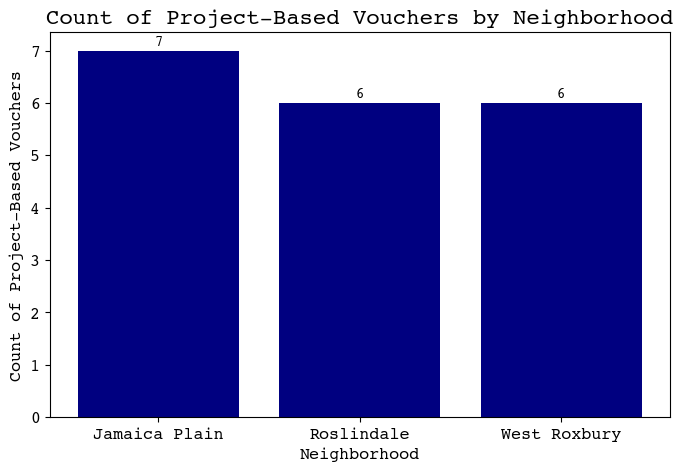

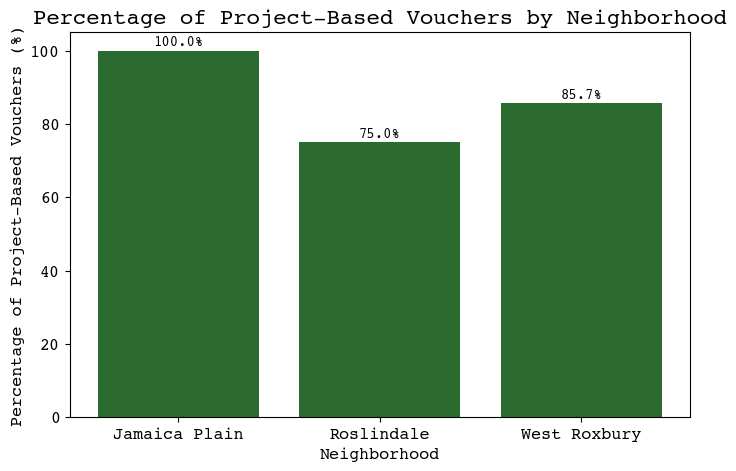

In [55]:
# Count of PBV families per neighborhood
pbv_counts = df.groupby('neighborhood')['PB_subsidy'].sum()
total_counts = df['neighborhood'].value_counts()
pbv_percentage = (pbv_counts / total_counts) * 100

# Plot 1: Count of Families with PBV
plt.figure(figsize=(8, 5))
bars = plt.bar(pbv_counts.index, pbv_counts, color='navy')

# Adding count on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.05, int(yval), ha='center', va='bottom', fontsize=10)

plt.xlabel("Neighborhood")
plt.ylabel("Count of Project-Based Vouchers")
plt.title("Count of Project-Based Vouchers by Neighborhood")
plt.xticks(rotation=0)
plt.show()

# Plot 2: Percentage of Families with PBV
plt.figure(figsize=(8, 5))
bars = plt.bar(pbv_percentage.index, pbv_percentage, color='#2C6B2F')

# Adding percentage on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.5, f'{yval:.1f}%', ha='center', va='bottom', fontsize=10)

plt.xlabel("Neighborhood")
plt.ylabel("Percentage of Project-Based Vouchers (%)")
plt.title("Percentage of Project-Based Vouchers by Neighborhood")
plt.xticks(rotation=0)
plt.show()

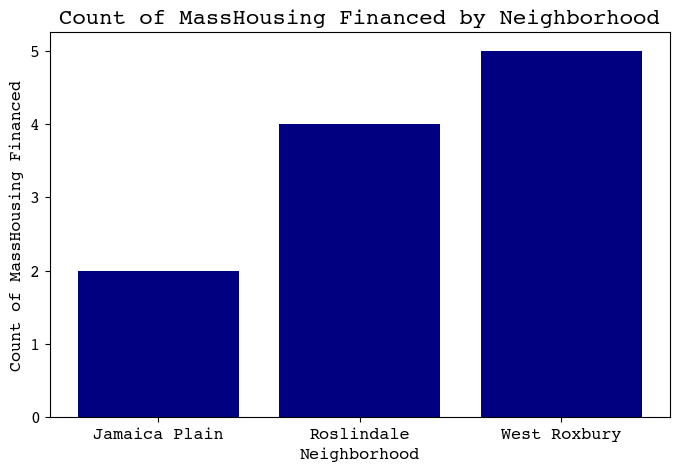

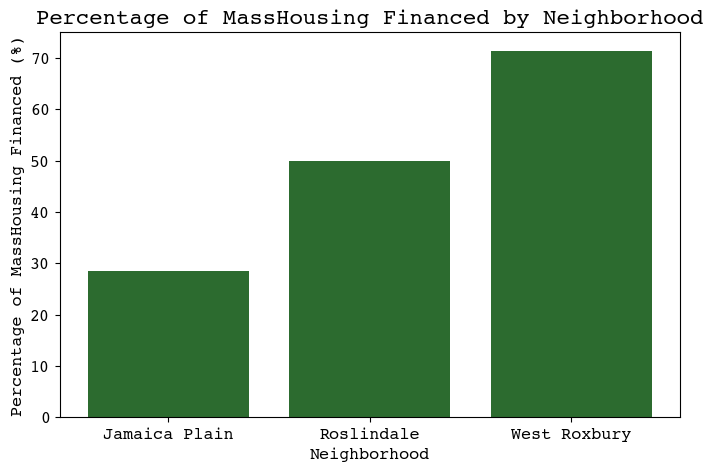

In [56]:
# Count of MH_financed per neighborhood
mh_counts = df.groupby('neighborhood')['MH_financed'].sum()
total_counts = df['neighborhood'].value_counts()
mh_percentage = (mh_counts / total_counts) * 100

# Plot 1: Count of Families with MH_financed
plt.figure(figsize=(8, 5))
plt.bar(mh_counts.index, mh_counts, color='navy')
plt.xlabel("Neighborhood")
plt.ylabel("Count of MassHousing Financed")
plt.title("Count of MassHousing Financed by Neighborhood")
plt.xticks(rotation=0)
plt.show()

# Plot 2: Percentage of Families with MH_financed
plt.figure(figsize=(8, 5))
plt.bar(mh_percentage.index, mh_percentage, color='#2C6B2F')
plt.xlabel("Neighborhood")
plt.ylabel("Percentage of MassHousing Financed (%)")
plt.title("Percentage of MassHousing Financed by Neighborhood")
plt.xticks(rotation=0)
plt.show()

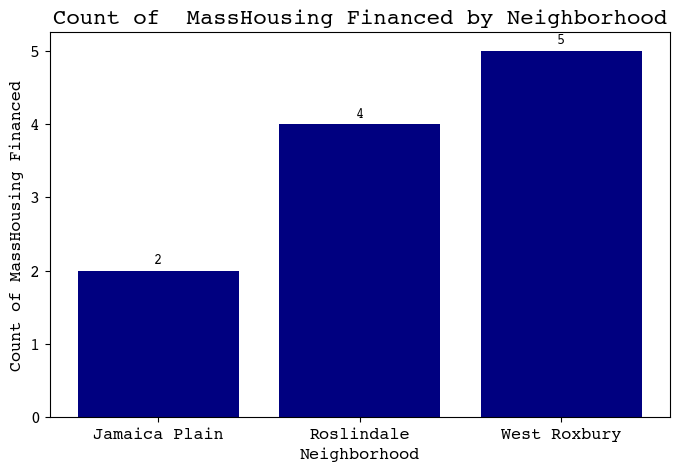

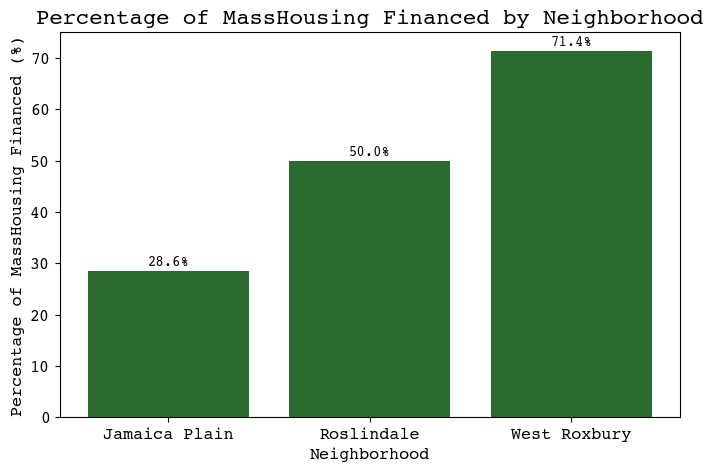

In [57]:
# Count of MH_financed per neighborhood
mh_counts = df.groupby('neighborhood')['MH_financed'].sum()
total_counts = df['neighborhood'].value_counts()
mh_percentage = (mh_counts / total_counts) * 100

# Plot 1: Count of Families with PBV
plt.figure(figsize=(8, 5))
bars = plt.bar(mh_counts.index, mh_counts, color='navy')

# Adding count on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.05, int(yval), ha='center', va='bottom', fontsize=10)

plt.xlabel("Neighborhood")
plt.ylabel("Count of MassHousing Financed")
plt.title("Count of  MassHousing Financed by Neighborhood")
plt.xticks(rotation=0)
plt.show()

# Plot 2: Percentage of Families with PBV
plt.figure(figsize=(8, 5))
bars = plt.bar(mh_percentage.index, mh_percentage, color='#2C6B2F')

# Adding percentage on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.5, f'{yval:.1f}%', ha='center', va='bottom', fontsize=10)

plt.xlabel("Neighborhood")
plt.ylabel("Percentage of MassHousing Financed (%)")
plt.title("Percentage of MassHousing Financed by Neighborhood")
plt.xticks(rotation=0)
plt.show()

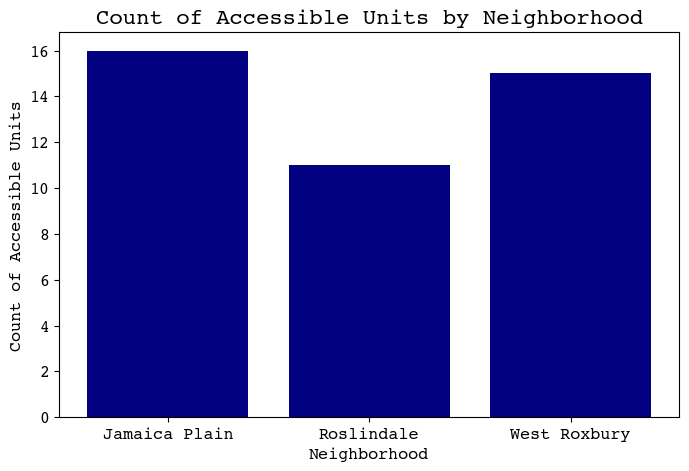

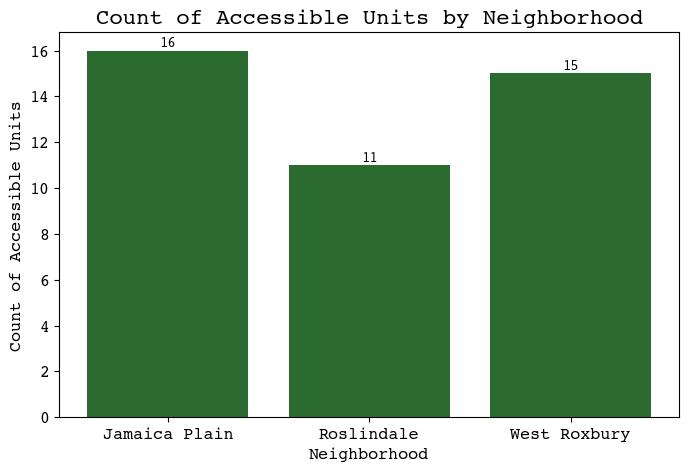

In [58]:
# Count of access units per neighborhood
access_counts = df.groupby('neighborhood')['access_units'].sum()
total_counts = df['neighborhood'].value_counts()

# Plot 1: Count of Access Units
plt.figure(figsize=(8, 5))
plt.bar(access_counts.index, access_counts, color='navy')
plt.xlabel("Neighborhood")
plt.ylabel("Count of Accessible Units")
plt.title("Count of Accessible Units by Neighborhood")
plt.xticks(rotation=0)
plt.show()

# Plot 2: Count of Access Units
plt.figure(figsize=(8, 5))
bars = plt.bar(access_counts.index, access_counts, color='#2C6B2F')

# Adding count on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.05, int(yval), ha='center', va='bottom', fontsize=10)

plt.xlabel("Neighborhood")
plt.ylabel("Count of Accessible Units")
plt.title("Count of Accessible Units by Neighborhood")
plt.xticks(rotation=0)
plt.show()

#### Elderly Housing EDA

In [59]:
df_elderly = df[df['ELD'] != 0]

In [60]:
df_elderly

,neighborhood,zip,name_of_development,masshousing_number,site_address,site_address_telephone_number,management_company,management_company_telephone_number,PB_subsidy,MH_financed,FAM,ELD,bedroom_size_0_1,bedroom_size_2_3,bedroom_size_4_and_more,access_units,POINT_X,POINT_Y
1,Jamaica Plain,2130,ANGELA WESTOVER HOUSE,00-105,49 PARLEY AVE,(617) 524-4520,"Peabody Properties, Inc.",(781) 794-1000,True,False,0,11,11,0,0,0,42.314007,-71.111019
3,Jamaica Plain,2130,FARNSWORTH HOUSE,00-167,90 SOUTH ST,(617) 524-6971,"Rogerson Communities, Inc.",(617) 469-5830,True,True,1,75,69,7,0,8,42.306748,-71.115079
10,Roslindale,2131,ROSLINDALE HOUSE,00-279,120 POPLAR ST,(617) 327-1503,"Rogerson Communities, Inc.",(617) 469-5830,True,True,1,83,83,1,0,4,42.284082,-71.128062
14,Roslindale,2130,WOODBOURNE APARTMENTS,00-330,6 SOUTHBOURNE RD,(617) 232-2807,"The Community Builders, Inc.",(617) 857-8772,True,True,1,74,69,6,0,0,42.290137,-71.117711
17,West Roxbury,2132,CHERITON GROVE,00-135,20 CHERITON RD,(617) 323-6109,"The Community Builders, Inc.",(401) 946-4868,True,True,0,60,60,0,0,3,42.260571,-71.155764
18,West Roxbury,2132,CHERITON HEIGHTS SENIO,10-012,20 CHERITON ROAD,(617) 323-6109,"The Community Builders, Inc.",(401) 946-4868,True,True,0,70,64,6,0,0,42.260571,-71.155764


#### Answering the Question: What housing options are available/deed restricted for elderly individuals?

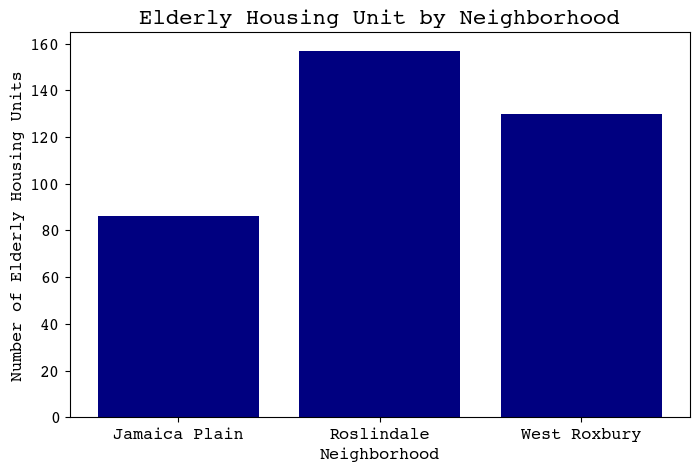

In [61]:
plt.figure(figsize=(8, 5))
df_elderly_sum = df_elderly.groupby('neighborhood')['ELD'].sum().reset_index()

plt.bar(df_elderly_sum['neighborhood'], df_elderly_sum['ELD'], color='navy')
plt.xlabel("Neighborhood")
plt.ylabel("Number of Elderly Housing Units")
plt.title("Elderly Housing Unit by Neighborhood")
plt.xticks(rotation=0)
plt.show()

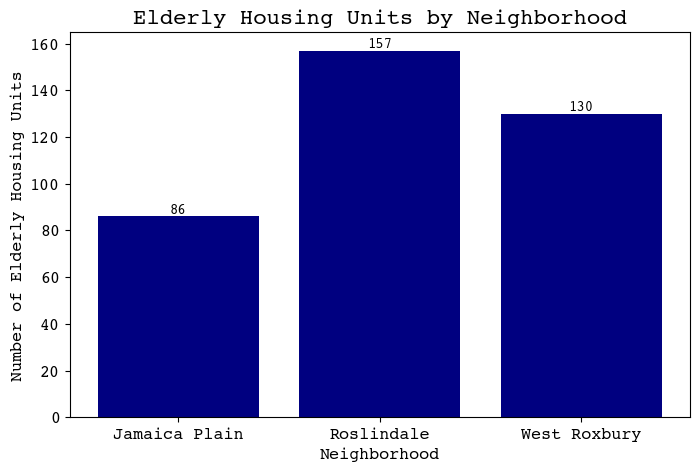

In [62]:
df_elderly_sum = df_elderly.groupby('neighborhood')['ELD'].sum().reset_index()

plt.figure(figsize=(8, 5))
bars = plt.bar(df_elderly_sum['neighborhood'], df_elderly_sum['ELD'], color='navy')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.05, int(yval), ha='center', va='bottom', fontsize=10)
    
plt.xlabel("Neighborhood")
plt.ylabel("Number of Elderly Housing Units")
plt.title("Elderly Housing Units by Neighborhood")
plt.xticks(rotation=0)
plt.show()

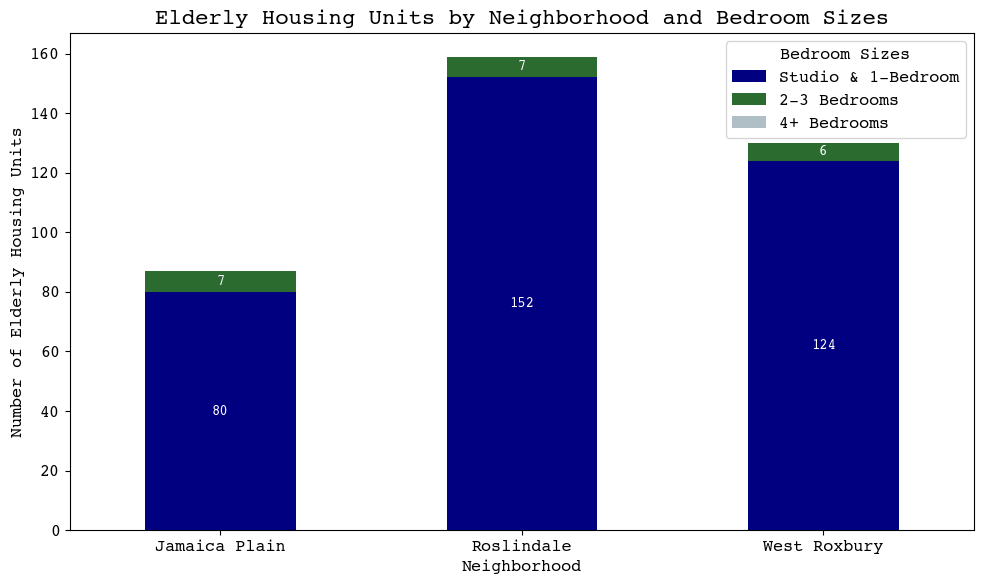

In [63]:
grouped_df_elderly = df_elderly.groupby('neighborhood')[['bedroom_size_0_1', 'bedroom_size_2_3', 'bedroom_size_4_and_more']].sum()
grouped_df_elderly = grouped_df_elderly.rename(columns={
    'bedroom_size_0_1': 'Studio & 1-Bedroom',
    'bedroom_size_2_3': '2-3 Bedrooms',
    'bedroom_size_4_and_more': '4+ Bedrooms'
})

ax = grouped_df_elderly.plot(kind='bar', stacked=True, figsize=(10, 6), color=['navy', '#2C6B2F', '#B0BEC5'])

ax.set_xlabel('Neighborhood')
ax.set_ylabel('Number of Elderly Housing Units')
ax.set_title('Elderly Housing Units by Neighborhood and Bedroom Sizes')
plt.legend(title='Bedroom Sizes')
plt.xticks(rotation=0)

for i, bars in enumerate(ax.containers):
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + height / 2,
                int(height),
                ha='center', va='center', fontsize=10, color='white'
            )

plt.tight_layout()
plt.show()

#### Map

In [64]:
# Normal map version

# !pip install folium
import folium
from folium.plugins import MarkerCluster
from IPython.display import IFrame

# Set map center (adjust as needed)
map_center = [42.3, -71.1]  

# Create Folium map
m = folium.Map(location=map_center, zoom_start=12)

# Add marker clustering
marker_cluster = MarkerCluster().add_to(m)

# Column name mapping for better readability
column_mapping = {
    'PB_subsidy': 'Project-Based Vouchers',
    'MH_financed': 'MassHousing Financed',
    'FAM': 'Family Units',
    'ELD': 'Elderly Units',
    'bedroom_size_0_1': 'Studio & 1-Bedroom',
    'bedroom_size_2_3': '2-3 Bedrooms',
    'bedroom_size_4_and_more': '4+ Bedrooms',
    'access_units': 'Accessible Units (As of Aug 2023)'
}

for _, row in df.iterrows():
    lat = row['POINT_X']
    lon = row['POINT_Y']
    
    # Format popup information
    popup_info = f"""
    <b>Site Address:</b> {row['site_address']}<br>
    <b>{column_mapping['PB_subsidy']}:</b> {row['PB_subsidy']}<br>
    <b>{column_mapping['MH_financed']}:</b> {row['MH_financed']}<br>
    <b>{column_mapping['FAM']}:</b> {row['FAM']}<br>
    <b>{column_mapping['ELD']}:</b> {row['ELD']}<br>
    <b>{column_mapping['bedroom_size_0_1']}:</b> {row['bedroom_size_0_1']}<br>
    <b>{column_mapping['bedroom_size_2_3']}:</b> {row['bedroom_size_2_3']}<br>
    <b>{column_mapping['bedroom_size_4_and_more']}:</b> {row['bedroom_size_4_and_more']}<br>
    <b>{column_mapping['access_units']}:</b> {row['access_units']}<br>
    """
    
    # Add marker with popup
    folium.Marker(
        location=[lat, lon],
        popup=folium.Popup(popup_info, max_width=300),
        icon=folium.Icon(color='red')
    ).add_to(marker_cluster)

# Save map as HTML
map_file_path = "elderly_housing_map.html"
m.save(map_file_path)

# Display map in notebook
IFrame(map_file_path, width=800, height=600)

In [65]:
# Heatmap version

# !pip install folium
import folium
from folium.plugins import MarkerCluster, HeatMap

# Ensure ZIP codes have leading zeros
df_elderly['zip'] = df_elderly['zip'].astype(str).str.zfill(5)

# Remove rows with missing latitude or longitude
df_elderly = df_elderly.dropna(subset=['POINT_X', 'POINT_Y'])

# Set map center around District 6
map_center = [42.3, -71.1] 
m = folium.Map(location=map_center, zoom_start=12)

heat_data = [[row['POINT_X'], row['POINT_Y'], row['ELD']] for _, row in df_elderly.iterrows()]
HeatMap(heat_data, radius=10, max_zoom=15).add_to(m)

# Add marker clustering
marker_cluster = MarkerCluster().add_to(m)

for _, row in df_elderly.iterrows():
    # Add marker to the cluster
    folium.Marker(
        location=[row['POINT_Y'], row['POINT_X']],
        icon=folium.Icon(color="red", icon="home")
    ).add_to(marker_cluster)

# Save the interactive map as an HTML file
map_file_path = "elderly_housing_heatmap.html"
m.save(map_file_path)

# Display the map in the notebook
IFrame(map_file_path, width=800, height=600)

/var/folders/5t/rl408cjx3wb2z3zq07qsqpnr0000gn/T/ipykernel_5715/2442677528.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_elderly['zip'] = df_elderly['zip'].astype(str).str.zfill(5)
